# PR #28731: changed files in the full tracked repository context

The review starts from **five changed files and five changed C++ functions**. The full tracked repository supplies the surrounding context: unchanged clients, forwarders, shared metadata contracts, build components, tests and configurations.

The current change-context section at the end of this notebook shows:

- unchanged join-order, statistics-extractor and test clients → aggregate-statistics API references → unchanged wrapper bodies → changed internal helper;
- unchanged optimizer callback dispatcher → possible `RewriteOrderedFirst` callback → changed aggregate rewrite;
- the shared `single_value_identity` contract connecting both changed C++ areas to an unchanged recursive-CTE reader and min/max producers;
- changed skip lists → effective exclusions inherited by unchanged optimizer-disabled and serializer configurations.

[Change-context findings and diagrams](/Users/kevintruong/project/SpurCode/docs/research/2026-11-18-pr28731-change-context.md)

Every context link retains its evidence type and a pinned source witness. Candidate references and contract participation are not promoted to compiler-resolved or runtime-impact edges.

The earlier C++ extraction baseline below remains supporting evidence. The current deliverable is the mapping from changes into the repository, not the extraction or binding totals. Production behavior remains unchanged.

In [27]:
# Baseline facts from the executed three-extension POC. No reclassification is assumed.
import json, hashlib, subprocess
from pathlib import Path
from collections import Counter
PRIOR = Path('/Users/kevintruong/project/SpurCode/docs/research/artifacts/2026-11-17-review-extensions-poc')
ARTIFACT = Path('/Users/kevintruong/project/SpurCode/docs/research/artifacts/2026-11-17-cpp-extraction-gap-lab')
ARTIFACT.mkdir(parents=True,exist_ok=True)
def save(name,data):
    (ARTIFACT/(name+'.json')).write_text(json.dumps(data,indent=2,default=str))
native_facts = json.loads((PRIOR/'native-facts.json').read_text())
after = [r for r in native_facts if r['side']=='after']
baseline_edges = []
for r in after:
    nodes={n['node_id']:n for n in r['facts']['nodes']}
    for e in r['facts']['edges']:
        if e['relation']=='calls':
            baseline_edges.append(dict(e,file_path=r['file_path'],source_sha256=r['source_sha256'],
                  caller_label=nodes.get(e['source_node_id'],{}).get('label'),
                  target_resolved=e['target_node_id'] in nodes))
assert len(baseline_edges)==366
assert sum(e['target_resolved'] for e in baseline_edges)==17
unresolved=[e for e in baseline_edges if not e['target_resolved']]
assert len(unresolved)==349
save('baseline-calls',baseline_edges)
save('baseline-identities',json.loads((PRIOR/'native-inputs.json').read_text()))
print('Baseline calls:',len(baseline_edges),'resolved:',17,'unresolved:',len(unresolved))
print('Unresolved evidence shapes:',Counter(('receiver' if e['receiver_text'] else 'scope' if e['scope_text'] else 'bare') for e in unresolved))
print('Common unresolved labels:',Counter(e['target_label'] for e in unresolved).most_common(20))
print('Receiver/scope samples:',[(e['target_label'],e['receiver_text'],e['scope_text'],e['caller_label']) for e in unresolved[:12]])


Baseline calls: 366 resolved: 17 unresolved: 349
Unresolved evidence shapes: Counter({'receiver': 233, 'bare': 87, 'scope': 29})
Common unresolved labels: [('size', 28), ('GetExpressionClass', 11), ('MinValue', 11), ('GetColumnBindings', 11), ('empty', 10), ('emplace_back', 7), ('move', 7), ('GetName', 7), ('Verify', 7), ('Binding', 7), ('MaxValue', 7), ('push_back', 6), ('GetReturnType', 6), ('SetSingleValueIdentity', 5), ('GetFirstFunction', 5), ('insert', 5), ('DistinctCount', 5), ('get_index', 4), ('GetArguments', 4), ('SetName', 4)]
Receiver/scope samples: [('GetOrderBys', 'input.aggregate', None, 'RewriteOrderedFirst'), ('unique_ptr_cast', None, None, 'RewriteOrderedFirst'), ('Copy', 'input.aggregate', None, 'RewriteOrderedFirst'), ('GetOrderBys', 'aggregate', None, 'RewriteOrderedFirst'), ('emplace_back', 'sort_children', None, 'RewriteOrderedFirst'), ('move', None, 'std', 'RewriteOrderedFirst'), ('make_uniq', None, None, 'RewriteOrderedFirst'), ('Value', None, None, 'RewriteOrd

In [7]:
use spur_graph::extract::languages::Language;
use spur_graph::extract::tree_sitter::BytesExtractor;
use std::path::Path;
let mut cpp_probe = BytesExtractor::for_language(Language::Cpp)?;
let cpp_symbols = cpp_probe.extract(Path::new("probe.cpp"), b"int add(int a, int b) { return a+b; }")?;
println!("actual_spur_graph_cpp_loaded: {:?}", cpp_symbols.iter().map(|s| &s.entity_name).collect::<Vec<_>>());


actual_spur_graph_cpp_loaded: ["add"]


In [28]:
# Partition by evidence actually present, not by guessed ownership/type.
categories = Counter()
classified=[]
for e in unresolved:
    if e['scope_text'] and (e['scope_text']=='std' or e['scope_text'].startswith('std::')):
        category='explicit_std_scope'
    elif e['receiver_text'] and '(' in e['receiver_text']:
        category='receiver_call_chain'
    elif e['receiver_text']:
        category='receiver_without_call_chain'
    elif e['scope_text']:
        category='explicit_non_std_scope'
    else:
        category='bare_name'
    categories[category]+=1
    classified.append(dict(e,syntactic_category=category,
                          semantic_owner_status='not_determined_from_name_alone'))
assert sum(categories.values())==349
save('baseline-syntactic-classification',classified)
save('baseline-category-counts',dict(categories))
print('Disjoint evidence categories:',dict(categories))
for category in categories:
    sample=[(r['target_label'],r['receiver_text'],r['scope_text']) for r in classified if r['syntactic_category']==category][:5]
    print(category,':',sample)


Disjoint evidence categories: {'receiver_without_call_chain': 211, 'bare_name': 87, 'explicit_std_scope': 8, 'receiver_call_chain': 22, 'explicit_non_std_scope': 21}
receiver_without_call_chain : [('GetOrderBys', 'input.aggregate', None), ('Copy', 'input.aggregate', None), ('GetOrderBys', 'aggregate', None), ('emplace_back', 'sort_children', None), ('GetOrderModifier', 'order', None)]
bare_name : [('unique_ptr_cast', None, None), ('make_uniq', None, None), ('Value', None, None), ('QualifiedName', None, None), ('NextPowerOfTwo', None, None)]
explicit_std_scope : [('move', None, 'std'), ('move', None, 'std'), ('move', None, 'std'), ('find', None, 'std'), ('move', None, 'std')]
receiver_call_chain : [('reset', 'aggregate->GetOrderBysMutable()', None), ('SetSingleValueIdentity', 'result->FunctionMutable()', None), ('HasSingleValueIdentity', 'aggregate->Function()', None), ('GetParameter', 'function.GetSignature()', None), ('SetType', 'function.GetSignature().GetParameter(0)', None)]
explic

In [29]:
# Ground the C++ fixtures with the installed compiler before extractor interpretation.
import shutil
FIXTURES = ARTIFACT/'fixtures'
FIXTURES.mkdir(exist_ok=True)
cases=json.loads(r'''[{"name":"bare_unique","cpp":"int leaf(){return 1;} int caller(){return leaf();}","purpose":"Positive local bare function"},{"name":"qualified_namespaces","cpp":"namespace a { int leaf(){return 1;} } namespace b { int leaf(){return 2;} } int caller(){return a::leaf()+b::leaf();}","purpose":"Positive qualified disambiguation"},{"name":"overload_set","cpp":"int pick(int x){return x;} double pick(double x){return x;} int caller(){return pick(1);} double caller_double(){return pick(1.0);}","purpose":"Overload selection needs argument/signature evidence"},{"name":"typed_receivers","cpp":"struct A { int run(){return 1;} }; struct B { int run(){return 2;} }; int caller(A &a,B &b){return a.run()+b.run();}","purpose":"C++ parameter types should select the correct method"},{"name":"qualified_miss","cpp":"namespace actual { int leaf(){return 1;} } namespace foreign { int leaf(); } int caller(){return foreign::leaf();}","purpose":"Explicit qualifier must not fall back to unrelated singleton"},{"name":"header_receiver","header":"namespace external { struct B { int run(); }; }","cpp":"#include \"api.hpp\"\nstruct A { int run(){return 1;} }; int caller(external::B &b){return b.run();}","purpose":"Single-file singleton must not contradict a receiver declared in a header"},{"name":"header_free_function","header":"inline int util(){return 7;}","cpp":"#include \"api.hpp\"\nint caller(){return util();}","purpose":"Compare single-file and selected-repository extraction"},{"name":"template_identity","cpp":"template<class T> T identity(T x){return x;} int caller(){return identity<int>(1);}","purpose":"Template/function duplicate identity affects resolution"},{"name":"qualified_member_templates","cpp":"namespace n { template<class T> T identity(T x){return x;} } struct A { template<class T> T apply(T x){return x;} }; int caller(A &a){return n::identity<int>(1)+a.apply<int>(2);}","purpose":"Qualified and member template call syntax coverage"},{"name":"custom_callback","cpp":"void callback(){} void invoke(void (*f)()){f();} void caller(){invoke(callback);}","purpose":"Callback values and indirect call targets remain distinct"},{"name":"function_pointer_shadow","cpp":"int target(){return 1;} int caller(int (*target)()){return target();}","purpose":"A function-pointer parameter shadows a same-name global function"},{"name":"macro_expansion","cpp":"#define RUN(f) f()\nvoid callback(){} void caller(){RUN(callback);}","purpose":"Macro call evidence differs from expanded callee"},{"name":"constructor","cpp":"struct A { A(){} }; A caller(){return A();}","purpose":"Construction has a separate relation and denominator"},{"name":"recursion","cpp":"int rec(int n){return n ? rec(n-1) : 0;}","purpose":"Self-call preservation"}]''')
compiler=shutil.which('clang++')
assert compiler, 'A C++ compiler is required to validate these fixtures'
compiler_version=subprocess.check_output([compiler,'--version'],text=True).splitlines()[0]
fixture_receipts=[]
for case in cases:
    root=FIXTURES/case['name']
    root.mkdir(exist_ok=True)
    (root/'probe.cpp').write_text(case['cpp']+'\n')
    if 'header' in case:
        (root/'api.hpp').write_text(case['header']+'\n')
    command=[compiler,'-std=c++17','-fsyntax-only','-Xclang','-ast-dump=json','-I'+str(root),str(root/'probe.cpp')]
    result=subprocess.run(command,text=True,capture_output=True,timeout=30)
    assert result.returncode==0,(case['name'],result.stderr)
    ast=json.loads(result.stdout)
    symbols={}
    def definitions(node,scope=()):
        kind=node.get('kind')
        name=node.get('name')
        current=scope
        if name and kind in ('NamespaceDecl','CXXRecordDecl') and not node.get('isImplicit'):
            current=scope+(name,)
        if name and kind in ('FunctionDecl','CXXMethodDecl','CXXConstructorDecl','CXXDestructorDecl','ParmVarDecl'):
            symbols[node['id']]={'name':'::'.join(scope+(name,)),'kind':kind,'type':node.get('type',{}).get('qualType'),
                                  'mangled_name':node.get('mangledName')}
            if kind!='ParmVarDecl':
                current=scope+(name,)
        for child in node.get('inner',[]):
            definitions(child,current)
    definitions(ast)
    def find_ref(node):
        if node.get('kind')=='DeclRefExpr':
            return node.get('referencedDecl',{}).get('id')
        if node.get('kind')=='MemberExpr':
            return node.get('referencedMemberDecl')
        for child in node.get('inner',[]):
            found=find_ref(child)
            if found:
                return found
        return None
    calls=[]
    def collect_calls(node):
        kind=node.get('kind')
        if kind in ('CallExpr','CXXMemberCallExpr','CXXOperatorCallExpr'):
            ref=find_ref(node.get('inner',[{}])[0])
            calls.append({'kind':kind,'target':symbols.get(ref),'range':node.get('range')})
        elif kind in ('CXXConstructExpr','CXXTemporaryObjectExpr'):
            calls.append({'kind':kind,'target':{'name':node.get('type',{}).get('qualType'),'kind':'construction'},'range':node.get('range')})
        for child in node.get('inner',[]):
            collect_calls(child)
    collect_calls(ast)
    fixture_receipts.append({'name':case['name'],'purpose':case['purpose'],'compiler':compiler_version,
                             'command':command,'exit_code':result.returncode,
                             'files':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(root.iterdir())},
                             'clang_calls':calls})
save('fixtures',cases)
save('compiler-ground-truth',fixture_receipts)
print('Compiler:',compiler_version)
print('Syntax-valid fixtures:',len(fixture_receipts))
for r in fixture_receipts:
    print(r['name'],[(c['kind'],c['target']) for c in r['clang_calls']])


Compiler: Apple clang version 17.0.0 (clang-1700.6.4.2)
Syntax-valid fixtures: 14
bare_unique [('CallExpr', {'name': 'leaf', 'kind': 'FunctionDecl', 'type': 'int ()', 'mangled_name': '__Z4leafv'})]
qualified_namespaces [('CallExpr', {'name': 'a::leaf', 'kind': 'FunctionDecl', 'type': 'int ()', 'mangled_name': '__ZN1a4leafEv'}), ('CallExpr', {'name': 'b::leaf', 'kind': 'FunctionDecl', 'type': 'int ()', 'mangled_name': '__ZN1b4leafEv'})]
overload_set [('CallExpr', {'name': 'pick', 'kind': 'FunctionDecl', 'type': 'int (int)', 'mangled_name': '__Z4picki'}), ('CallExpr', {'name': 'pick', 'kind': 'FunctionDecl', 'type': 'double (double)', 'mangled_name': '__Z4pickd'})]
typed_receivers [('CXXMemberCallExpr', {'name': 'A::run', 'kind': 'CXXMethodDecl', 'type': 'int ()', 'mangled_name': '__ZN1A3runEv'}), ('CXXMemberCallExpr', {'name': 'B::run', 'kind': 'CXXMethodDecl', 'type': 'int ()', 'mangled_name': '__ZN1B3runEv'})]
qualified_miss [('CallExpr', {'name': 'foreign::leaf', 'kind': 'FunctionDec

In [6]:
println!("factory_rust_ready");

factory_rust_ready


## What the source says before measurement

`BytesExtractor::extract_file_facts` creates a fresh fact builder for one source file. It does not load headers or a repository index. `build_facts_for_paths` instead shares a builder across selected files; this still does not provide a C++ translation-unit model.

The current C++ queries capture ordinary bare, qualified and member calls, plus bare template calls. Qualified/member template forms need measurement. The generic typed-binding collector accepts `parameter` and `let_declaration`, which do not match the main C++ declaration forms. `PendingEdge` retains a name, receiver and scope, but lacks call-site coordinates, argument types and a resolution reason.

Two precision hypotheses are especially important: an explicit C++ qualifier miss can reach bare-name fallback; a function-pointer parameter can shadow a same-named global. The compiler fixtures above establish expected references before the Rust probe runs.

**Research boundary:** syntax extraction, compiler binding and whole-program possible execution are different layers. The 17/349 baseline is a graph-fact count until call-site identity and query overlap are audited.

In [30]:
import duckdb, json, pathlib, sys
assert duckdb.__version__=='2.0.0', duckdb.__version__
CPP_PACKAGE=pathlib.Path('/Users/kevintruong/project/SpurCode/.spur/artifacts/review-extensions-poc/extensions/v2.0.0/osx_arm64/spur_graph.duckdb_extension')
cpp_extension_probe=duckdb.connect(config={'allow_unsigned_extensions':True})
cpp_extension_probe.execute("LOAD '"+str(CPP_PACKAGE).replace("'","''")+"'")
cpp_extension_info=cpp_extension_probe.execute('SELECT spur_graph_info()').fetchone()[0]
cpp_native_result=cpp_extension_probe.execute("SELECT spur_graph_file_facts_result('probe.cpp','int leaf(){return 1;} int caller(){return leaf();}')").fetchone()[0]
print('DuckDB:',duckdb.__version__,'Python:',sys.executable)
print('Extension:',json.dumps(cpp_extension_info,default=str))
print('Native result keys:',list(cpp_native_result))
print('Example result:',json.dumps(cpp_native_result,default=str)[:2500])

DuckDB: 2.0.0 Python: /Users/kevintruong/.spur/jupyter/venv-duckdb-2.0/bin/python
Extension: {"extension_version": "0.1.0", "facts_schema_version": 1, "duckdb_api_version": "2.0.0", "extractor_id": "source-sha256-v1:6ff57778ccc62a9cbd78f39549836fd9a7c91f55c3f94830443b239e8a17f2c2", "supported_languages": ["C", "Cpp", "Css", "Go", "Hcl", "Html", "Javascript", "Json", "JupyterNotebook", "Lua", "Markdown", "Mermaid", "Python", "Rust", "Shell", "Sql", "Terraform", "Toml", "Tsx", "TypeScript", "Yaml"], "resolution_scope": "single_file"}
Native result keys: ['status', 'error_code', 'error_message', 'facts']
Example result: {"status": "ok", "error_code": null, "error_message": null, "facts": {"nodes": [{"node_id": 1, "stable_key": "3f2bbb39def82256", "label": "probe.cpp", "kind": "file", "file_id": 1, "source_span_id": 1, "first_seen_run_id": 1}, {"node_id": 2, "stable_key": "fc199ddf9e464d60", "label": "leaf", "kind": "function", "file_id": 1, "source_span_id": 2, "first_seen_run_id": 1}, {"

## Main experiment: repository snapshots through the extension

Use the complete Git tree at PR base `629e395a854d72dcb1f414e1a0451c68ac0e9f1f` and head `d29b26bb92ac940a0807be0f43cc385b31623839`. Inventory every tracked entry. This C++ investigation parses **every tracked C++/header form** across `src`, `extension`, `test`, `third_party`, `tools`, examples and benchmarks; it does not restrict extraction to changed files. Neighboring unsupported suffixes receive explicit diagnostics. Other languages remain in the manifest and outside this C++ extraction scope.

The worker executes the actual typed SQL function `spur_graph_file_facts_result(logical_path, source)` and stores its native results. Unchanged `(blob, path, extractor)` inputs are reused between base and head. All node/edge joins retain snapshot, path, blob and extractor identity.

`spur_graph_info()` reports `resolution_scope = single_file`. Therefore full repository indexing and cross-file binding are measured separately. The name inventory is candidate evidence only; it does not create graph relationships.

In [31]:
import subprocess, pathlib, json, sys, hashlib
LAB=pathlib.Path('/Users/kevintruong/project/SpurCode/docs/research/artifacts/2026-11-17-cpp-extraction-gap-lab')
REPO_INDEX=pathlib.Path('/Users/kevintruong/project/SpurCode/.spur/artifacts/cpp-gap-repository-index')
REPO_INDEX.mkdir(parents=True,exist_ok=True)
repo_probe_script=LAB/'repo_extension_probe.py'
repo_probe_command=[sys.executable,str(repo_probe_script),'--repo','/Users/kevintruong/project/duckdb','--base','629e395a854d72dcb1f414e1a0451c68ac0e9f1f','--head','d29b26bb92ac940a0807be0f43cc385b31623839','--package',str(CPP_PACKAGE),'--out',str(REPO_INDEX)]
if 'repo_probe_process' in globals() and repo_probe_process.poll() is None:
    print('Repository extraction already running:',repo_probe_process.pid)
else:
    # Release this notebook's read-only attachment before the worker opens its cache.
    duckdb.sql('DETACH IF EXISTS cpp_repository')
    repo_probe_log=open(REPO_INDEX/'worker.log','a')
    repo_probe_process=subprocess.Popen(repo_probe_command,stdout=repo_probe_log,stderr=subprocess.STDOUT)
    launch_receipt={'command':repo_probe_command,'pid':repo_probe_process.pid,'script_sha256':hashlib.sha256(repo_probe_script.read_bytes()).hexdigest(),'package_sha256':hashlib.sha256(CPP_PACKAGE.read_bytes()).hexdigest()}
    (LAB/'repository-launch.json').write_text(json.dumps(launch_receipt,indent=2))
    print(json.dumps(launch_receipt,indent=2))
print('Progress:',REPO_INDEX/'progress.json')

{
  "command": [
    "/Users/kevintruong/.spur/jupyter/venv-duckdb-2.0/bin/python",
    "/Users/kevintruong/project/SpurCode/docs/research/artifacts/2026-11-17-cpp-extraction-gap-lab/repo_extension_probe.py",
    "--repo",
    "/Users/kevintruong/project/duckdb",
    "--base",
    "629e395a854d72dcb1f414e1a0451c68ac0e9f1f",
    "--head",
    "d29b26bb92ac940a0807be0f43cc385b31623839",
    "--package",
    "/Users/kevintruong/project/SpurCode/.spur/artifacts/review-extensions-poc/extensions/v2.0.0/osx_arm64/spur_graph.duckdb_extension",
    "--out",
    "/Users/kevintruong/project/SpurCode/.spur/artifacts/cpp-gap-repository-index"
  ],
  "pid": 34949,
  "script_sha256": "4a879db30ad7ed39ec89f39c0f28c11f683872cc161348266d1a1574a9d33871",
  "package_sha256": "41f5e65ad778a4e90d513ef5dc2f5065d0f45629968a20a231ece962e9bf627f"
}
Progress: /Users/kevintruong/project/SpurCode/.spur/artifacts/cpp-gap-repository-index/progress.json


In [7]:
// Execute the actual Rust extractor through the required project wrapper.
// The research example calls BytesExtractor::extract_file_facts and build_facts_for_paths.
use std::process::Command;
let cpp_workspace = "/Users/kevintruong/project/SpurCode";
let cpp_lab_dir = format!("{cpp_workspace}/docs/research/artifacts/2026-11-17-cpp-extraction-gap-lab");
let cpp_probe_output = Command::new(format!("{cpp_workspace}/scripts/spur-cargo"))
    .current_dir(cpp_workspace)
    .env("SPUR_NO_LOCAL_FALLBACK", "1")
    .env("PATH", format!("/opt/homebrew/bin:{}", std::env::var("PATH").unwrap_or_default()))
    .args(["run", "-p", "spur-graph", "--no-default-features", "--example", "cpp_gap_probe", "--", "crates/spur-graph/examples/cpp_gap_probe_result.json"])
    .output()?;
std::fs::write(format!("{cpp_lab_dir}/rust-notebook-stdout.log"), &cpp_probe_output.stdout)?;
std::fs::write(format!("{cpp_lab_dir}/rust-notebook-stderr.log"), &cpp_probe_output.stderr)?;
println!("remote Rust probe exit: {}", cpp_probe_output.status);
let cpp_stdout = String::from_utf8_lossy(&cpp_probe_output.stdout).into_owned();
println!("{}", cpp_stdout.lines().filter(|s| s.contains("cpp_gap_probe_v1") || s.contains("remote cargo exited")).collect::<Vec<_>>().join("\n"));
assert!(cpp_probe_output.status.success(), "inspect rust-notebook stdout/stderr logs");
let cpp_result_bytes = std::fs::read(format!("{cpp_workspace}/crates/spur-graph/examples/cpp_gap_probe_result.json"))?;
std::fs::write(format!("{cpp_lab_dir}/rust-core-probes.json"), &cpp_result_bytes)?;
println!("actual Rust core results: {} bytes", cpp_result_bytes.len());

remote Rust probe exit: exit status: 0


cpp_gap_probe_v1: 14 fixtures and 2 pinned real files -> crates/spur-graph/examples/cpp_gap_probe_result.json


actual Rust core results: 881519 bytes


In [32]:
# Measure research-consumer overhead before adjusting its transaction strategy.
import time, statistics, tempfile
perf_source='int leaf(){return 1;} int caller(){return leaf();}'
perf_file=pathlib.Path(tempfile.mkdtemp(prefix='cpp-gap-timing-'))/'probe.duckdb'
perf_con=duckdb.connect(str(perf_file),config={'allow_unsigned_extensions':True})
perf_con.execute("LOAD '"+str(CPP_PACKAGE).replace("'","''")+"'")
perf_con.execute("CREATE TABLE timings AS SELECT 0::INTEGER i, spur_graph_file_facts_result('probe.cpp','') result WHERE false")
perf_samples={}
for mode in ['native_select','autocommit_insert','transaction_insert']:
    durations=[]
    if mode=='transaction_insert': perf_con.execute('BEGIN')
    for i in range(len(cases)):
        begin=time.perf_counter()
        if mode=='native_select':
            perf_con.execute("SELECT spur_graph_file_facts_result('probe.cpp',?)",[perf_source]).fetchone()
        else:
            perf_con.execute("INSERT INTO timings SELECT ?,spur_graph_file_facts_result('probe.cpp',?)",[i,perf_source])
        durations.append(time.perf_counter()-begin)
    if mode=='transaction_insert': perf_con.execute('COMMIT')
    perf_samples[mode]={'samples':len(durations),'median_seconds':statistics.median(durations),'total_seconds':sum(durations),'durations':durations}
perf_con.close()
save('consumer-timing',perf_samples)
print(json.dumps({mode:{k:v for k,v in data.items() if k!='durations'} for mode,data in perf_samples.items()},indent=2))

{
  "native_select": {
    "samples": 14,
    "median_seconds": 0.42805816650070483,
    "total_seconds": 5.971522166997602
  },
  "autocommit_insert": {
    "samples": 14,
    "median_seconds": 0.5754012500001409,
    "total_seconds": 7.768061126997054
  },
  "transaction_insert": {
    "samples": 14,
    "median_seconds": 0.633946291999564,
    "total_seconds": 9.715213709998352
  }
}


In [33]:
# Same native function and sources, now one row-batched SQL query.
batch_begin=time.perf_counter()
batch_outputs=cpp_extension_probe.execute("SELECT spur_graph_file_facts_result(logical_path,source) FROM (SELECT unnest(?) logical_path,unnest(?) source)",[[f'bench_{i}.cpp' for i in range(len(cases))],[perf_source]*len(cases)]).fetchall()
batch_elapsed=time.perf_counter()-batch_begin
assert len(batch_outputs)==len(cases) and all(row[0]['status']=='ok' for row in batch_outputs)
perf_samples['one_sql_batch']={'samples':len(batch_outputs),'total_seconds':batch_elapsed,'seconds_per_row':batch_elapsed/len(batch_outputs)}
save('consumer-timing',perf_samples)
print(json.dumps(perf_samples['one_sql_batch'],indent=2))

{
  "samples": 14,
  "total_seconds": 0.6292378749985801,
  "seconds_per_row": 0.044945562499898575
}


In [34]:
# Historical pilot receipt: no process is stopped when replaying the finished lab.
print('The original per-file SQL pilot was intentionally stopped after 735 cached inputs.')
print((LAB/'repository-pilot-progress.json').read_text())
print('The completed scan uses SQL row batches by source directory, with the same native function.')

The original per-file SQL pilot was intentionally stopped after 735 cached inputs.
{
  "state": "indexing",
  "completed_this_run": 735,
  "pending_at_start": 4926,
  "last_file": "src/include/duckdb/planner/column_binding_map.hpp",
  "elapsed_seconds": 277.91172091599947
}

The completed scan uses SQL row batches by source directory, with the same native function.


In [35]:
# End-to-end extension parity for the same compiler-validated Rust fixtures.
core_probe=json.loads((LAB/'rust-core-probes.json').read_text())
fixture_sql=cpp_extension_probe.execute("SELECT spur_graph_file_facts_result(logical_path,source) FROM (SELECT unnest(?) logical_path,unnest(?) source)",[['probe.cpp']*len(cases),[case['cpp']+'\n' for case in cases]]).fetchall()
def value_defaults(value):
    if isinstance(value,dict): return {k:value_defaults(v) for k,v in value.items() if v is not None}
    if isinstance(value,list): return [value_defaults(v) for v in value]
    return value
def node_evidence(facts,node_id,source):
    node=next((n for n in facts['nodes'] if n['node_id']==node_id),None)
    if node is None: return None
    span=next((s for s in facts['spans'] if s['span_id']==node['source_span_id']),None)
    parents={e['target_node_id']:e['source_node_id'] for e in facts['edges'] if e['relation']=='contains'}
    nodes={n['node_id']:n for n in facts['nodes']}
    chain=[node['label']]; parent=parents.get(node_id); seen={node_id}
    while parent in nodes and parent not in seen and nodes[parent]['kind']!='file':
        seen.add(parent); chain.append(nodes[parent]['label']); parent=parents.get(parent)
    return {'node_id':node_id,'name':'::'.join(reversed(chain)),'kind':node['kind'],
            'definition':source.encode()[span['start_byte']:span['end_byte']].decode() if span else None}
fixture_results=[]
for case,core,sql_row in zip(cases,core_probe['fixtures'],fixture_sql):
    assert case['name']==core['name']
    native=sql_row[0]; assert native['status']=='ok',(case['name'],native)
    for field in ['nodes','edges','spans']:
        assert value_defaults(native['facts'][field])==value_defaults(core['single_file']['facts'][field]),(case['name'],field)
    calls=[]
    for edge in native['facts']['edges']:
        if edge['relation'] in ['calls','constructs','references']:
            calls.append({'relation':edge['relation'],'label':edge['target_label'],'receiver':edge['receiver_text'],'scope':edge['scope_text'],'bind_method':edge['bind_method'],
                'caller':node_evidence(native['facts'],edge['source_node_id'],case['cpp']+'\n'),
                'target':node_evidence(native['facts'],edge['target_node_id'],case['cpp']+'\n')})
    fixture_results.append({'name':case['name'],'native_status':native['status'],'rust_extension_parity':True,
                           'syntax_calls':core['single_file']['syntax_calls'],'native_calls':calls})
save('fixture-extension-results',fixture_results)
print('Actual Rust / native extension parity:',len(fixture_results),'fixtures')
for result in fixture_results:
    print(result['name'],'AST:',len(result['syntax_calls']),[(e['label'],(e['target'] or {}).get('name'),e['bind_method']) for e in result['native_calls']])
print('Overload witnesses:',[e for r in fixture_results if r['name']=='overload_set' for e in r['native_calls']])
real_syntax=[]
for real in core_probe['real_files']:
    data=real['single_file']; edges=[e for e in data['facts']['edges'] if e['relation']=='calls']
    real_syntax.append({'path':data['logical_path'],'source_sha256':data['source_sha256'],'syntax_call_expressions':len(data['syntax_calls']),
                        'emitted_call_facts':len(edges),'bound':sum(e.get('target_node_id') is not None for e in edges),
                        'callee_shapes':dict(Counter(e['callee_kind'] for e in data['syntax_calls']))})
save('real-syntax-counts',real_syntax)
print('Real syntax versus fact counts:',json.dumps(real_syntax,indent=2))

Actual Rust / native extension parity: 14 fixtures
bare_unique AST: 1 [('leaf', 'leaf', 'singleton')]
qualified_namespaces AST: 2 [('leaf', 'a::leaf', 'fqn'), ('leaf', 'b::leaf', 'fqn')]
overload_set AST: 2 [('pick', 'pick', 'same_file_duplicate'), ('pick', 'pick', 'same_file_duplicate')]
typed_receivers AST: 2 [('run', None, None), ('run', None, None)]
qualified_miss AST: 1 [('leaf', 'actual::leaf', 'bare_qualified_singleton')]
header_receiver AST: 1 [('run', 'A::run', 'method_crate_singleton')]
header_free_function AST: 1 [('util', None, None)]
template_identity AST: 1 [('identity', None, None)]
qualified_member_templates AST: 2 []
custom_callback AST: 2 [('f', None, None), ('invoke', 'invoke', 'singleton')]
function_pointer_shadow AST: 1 [('target', 'target', 'singleton')]
macro_expansion AST: 1 [('RUN', None, None)]
constructor AST: 1 [('A', None, None)]
recursion AST: 1 []
Overload witnesses: [{'relation': 'calls', 'label': 'pick', 'receiver': None, 'scope': None, 'bind_method': '

In [36]:
# Inspect full-repository completion without treating a successful launch as completion.
import time
while repo_probe_process.poll() is None:
    time.sleep(1)
repo_probe_exit=repo_probe_process.poll()
print('Worker exit:',repo_probe_exit)
print((REPO_INDEX/'progress.json').read_text())
if repo_probe_exit is not None:
    print((REPO_INDEX/'worker.log').read_text()[-1000:])
    assert repo_probe_exit==0, 'inspect worker.log; a failed worker does not complete repository acceptance'
    repo_summary=json.loads((REPO_INDEX/'summary.json').read_text())
    save('repository-summary',repo_summary)
    print(json.dumps(repo_summary,indent=2))

Worker exit: 0
{
  "state": "completed",
  "completed_this_run": 0
}

  "zero": 41,
    "one": 56,
    "many": 252
  },
  "elapsed_seconds_this_run": 2.028481166000347,
  "identities": {
    "base": "629e395a854d72dcb1f414e1a0451c68ac0e9f1f",
    "head": "d29b26bb92ac940a0807be0f43cc385b31623839",
    "package_sha256": "41f5e65ad778a4e90d513ef5dc2f5065d0f45629968a20a231ece962e9bf627f",
    "info": {
      "extension_version": "0.1.0",
      "facts_schema_version": 1,
      "duckdb_api_version": "2.0.0",
      "extractor_id": "source-sha256-v1:6ff57778ccc62a9cbd78f39549836fd9a7c91f55c3f94830443b239e8a17f2c2",
      "supported_languages": [
        "C",
        "Cpp",
        "Css",
        "Go",
        "Hcl",
        "Html",
        "Javascript",
        "Json",
        "JupyterNotebook",
        "Lua",
        "Markdown",
        "Mermaid",
        "Python",
        "Rust",
        "Shell",
        "Sql",
        "Terraform",
        "Toml",
        "Tsx",
        "TypeScript",
      

In [37]:
# Materialize only the pinned C++ source inventory for a diagnostic shared-builder comparison.
# This does not change the user's DuckDB checkout.
FROZEN_CPP=REPO_INDEX/'head-cpp-sources'
FROZEN_CPP.mkdir(exist_ok=True)
with duckdb.connect(str(REPO_INDEX/'repository.duckdb'),read_only=True) as check_con:
    cpp_head_rows=check_con.execute("SELECT logical_path,blob_oid,source_sha256 FROM indexed_sources WHERE snapshot='head' ORDER BY logical_path").fetchall()
cpp_reader=subprocess.Popen(['git','-C','/Users/kevintruong/project/duckdb','cat-file','--batch'],stdin=subprocess.PIPE,stdout=subprocess.PIPE)
try:
    for logical_path,oid,expected_sha in cpp_head_rows:
        assert '\n' not in logical_path
        target=FROZEN_CPP/logical_path
        assert target.resolve().is_relative_to(FROZEN_CPP.resolve())
        cpp_reader.stdin.write((oid+'\n').encode());cpp_reader.stdin.flush()
        actual_oid,kind,length=cpp_reader.stdout.readline().decode().strip().split()
        data=cpp_reader.stdout.read(int(length)); assert cpp_reader.stdout.read(1)==b'\n'
        assert actual_oid==oid and kind=='blob' and hashlib.sha256(data).hexdigest()==expected_sha
        target.parent.mkdir(parents=True,exist_ok=True);target.write_bytes(data)
finally:
    cpp_reader.stdin.close();cpp_reader.wait(timeout=10)
(REPO_INDEX/'head-cpp-paths.txt').write_text('\n'.join(row[0] for row in cpp_head_rows)+'\n')
print('Frozen head C++ inputs:',len(cpp_head_rows),'all verified against SQL cache identities')

Frozen head C++ inputs: 4924 all verified against SQL cache identities


In [8]:
// Diagnostic comparison: the existing shared Rust builder over the same full head inventory.
// This is a core API experiment; the extension still reports single_file.
use spur_graph::extract::tree_sitter::build_facts_for_paths;
use spur_graph::schema::{NodeKind, RelationKind};
{
    let cpp_index_root = std::path::Path::new("/Users/kevintruong/project/SpurCode/.spur/artifacts/cpp-gap-repository-index");
    let cpp_head_paths: Vec<std::path::PathBuf> = std::fs::read_to_string(cpp_index_root.join("head-cpp-paths.txt"))?
        .lines().map(std::path::PathBuf::from).collect();
    let cpp_build_started = std::time::Instant::now();
    let cpp_full_graph = build_facts_for_paths(&cpp_index_root.join("head-cpp-sources"), &cpp_head_paths)?;
    let cpp_nodes: std::collections::HashMap<_, _> = cpp_full_graph.nodes.iter().map(|n| (n.node_id,n)).collect();
    let cpp_files: std::collections::HashMap<_, _> = cpp_full_graph.nodes.iter()
        .filter(|n| n.kind==NodeKind::File).filter_map(|n| n.file_id.map(|id| (id,n.label.as_str()))).collect();
    let cpp_seed_files: std::collections::HashSet<_> = cpp_full_graph.nodes.iter()
        .filter(|n| n.kind==NodeKind::File &&
            (n.label.ends_with("src/function/aggregate/distributive/first_last_any.cpp") ||
             n.label.ends_with("src/optimizer/relation_statistics/relation_statistics_helper.cpp")))
        .filter_map(|n| n.file_id).collect();
    assert_eq!(cpp_seed_files.len(),2);
    let cpp_calls: Vec<_> = cpp_full_graph.edges.iter().filter(|e| e.relation==RelationKind::Calls).collect();
    let cpp_cross_file = |e: &spur_graph::schema::GraphEdge| -> bool {
        let src=cpp_nodes.get(&e.source_node_id).and_then(|n| n.file_id);
        let dst=e.target_node_id.and_then(|id| cpp_nodes.get(&id)).and_then(|n| n.file_id);
        src.is_some() && dst.is_some() && src!=dst
    };
    let cpp_seed_calls: Vec<_> = cpp_calls.iter().copied()
        .filter(|e| cpp_nodes.get(&e.source_node_id).and_then(|n| n.file_id).is_some_and(|id| cpp_seed_files.contains(&id))).collect();
    // A larger symbol inventory can reclassify calls as construction; measure both.
    let cpp_seed_constructs = cpp_full_graph.edges.iter().filter(|e| e.relation==RelationKind::Constructs &&
        cpp_nodes.get(&e.source_node_id).and_then(|n|n.file_id).is_some_and(|id|cpp_seed_files.contains(&id))).count();
    let cpp_core_summary = format!(
        "{{\"scope\":\"existing shared Rust builder over pinned head C++ sources\",\"files\":{},\"nodes\":{},\"call_facts\":{},\"bound\":{},\"cross_file_bound\":{},\"changed_call_facts\":{},\"changed_construct_facts\":{},\"changed_bound\":{},\"changed_cross_file_bound\":{},\"elapsed_seconds\":{}}}",
        cpp_head_paths.len(),cpp_full_graph.nodes.len(),cpp_calls.len(),
        cpp_calls.iter().filter(|e|e.target_node_id.is_some()).count(),
        cpp_calls.iter().filter(|e|cpp_cross_file(e)).count(),
        cpp_seed_calls.len(),cpp_seed_constructs,cpp_seed_calls.iter().filter(|e|e.target_node_id.is_some()).count(),
        cpp_seed_calls.iter().filter(|e|cpp_cross_file(e)).count(),
        cpp_build_started.elapsed().as_secs_f64());
    std::fs::write("/Users/kevintruong/project/SpurCode/docs/research/artifacts/2026-11-17-cpp-extraction-gap-lab/rust-full-repository-summary.json",&cpp_core_summary)?;
    let cpp_witnesses: Vec<_> = cpp_seed_calls.iter().filter_map(|e| {
        let src=cpp_nodes.get(&e.source_node_id)?;
        let dst=e.target_node_id.and_then(|id| cpp_nodes.get(&id))?;
        Some(format!("{} :: {} -> {} :: {} [bind={:?}, cross_file={}]",
            src.file_id.and_then(|id|cpp_files.get(&id)).unwrap_or(&"?"),src.label,
            dst.file_id.and_then(|id|cpp_files.get(&id)).unwrap_or(&"?"),dst.label,e.bind_method,cpp_cross_file(e)))
    }).collect();
    std::fs::write("/Users/kevintruong/project/SpurCode/docs/research/artifacts/2026-11-17-cpp-extraction-gap-lab/rust-full-repository-seed-witnesses.txt",cpp_witnesses.join("\n"))?;
    println!("{}",cpp_core_summary);
}

{"scope":"existing shared Rust builder over pinned head C++ sources","files":4924,"nodes":156494,"call_facts":229688,"bound":43289,"cross_file_bound":27314,"changed_call_facts":353,"changed_construct_facts":13,"changed_bound":69,"changed_cross_file_bound":53,"elapsed_seconds":54.670626791}


()

In [38]:
LOAD '/Users/kevintruong/project/SpurCode/.spur/artifacts/review-extensions-poc/extensions/v2.0.0/osx_arm64/spur_graph.duckdb_extension';
WITH native AS (
  SELECT spur_graph_info() AS info,
         spur_graph_file_facts_result('proof.cpp', 'int leaf(){return 1;} int caller(){return leaf();}') AS result
)
SELECT version() AS duckdb_version, info.extension_version AS extension_version,
       info.resolution_scope AS resolution_scope, result.status AS status,
       len(result.facts.nodes) AS nodes, len(result.facts.edges) AS edges
FROM native;

duckdb_version,extension_version,resolution_scope,status,nodes,edges
v2.0.0,0.1.0,single_file,ok,3,3


In [39]:
ATTACH IF NOT EXISTS '/Users/kevintruong/project/SpurCode/.spur/artifacts/cpp-gap-repository-index/repository.duckdb' AS cpp_repository (READ_ONLY);
SELECT snapshot, count(*) AS call_facts,
       count(*) FILTER (WHERE target_node_id IS NOT NULL) AS bound,
       count(*) FILTER (WHERE target_node_id IS NULL) AS unresolved
FROM cpp_repository.edges
WHERE relation = 'calls'
GROUP BY snapshot
ORDER BY snapshot;

snapshot,call_facts,bound,unresolved
base,230702,20546,210156
head,230744,20551,210193


In [40]:
# Validate the repository consumer and distinguish it from the shared core experiment.
with duckdb.connect(str(REPO_INDEX/'repository.duckdb'),read_only=True) as repo_check:
    def query_rows(sql):
        result=repo_check.execute(sql); names=[d[0] for d in result.description]
        return [dict(zip(names,row)) for row in result.fetchall()]
    repo_validation={
      'cache_keys':query_rows('SELECT count(*) inputs,count(DISTINCT (logical_path,blob_oid,extractor_id)) unique_keys FROM extraction_cache'),
      'node_counts':query_rows('SELECT snapshot,count(*) nodes FROM nodes GROUP BY snapshot'),
      'empty_sources':query_rows("SELECT snapshot,logical_path FROM indexed_sources WHERE result.status='empty_source'"),
      'candidate_shapes':query_rows("SELECT CASE WHEN coalesce(i.raw_candidate_nodes,0)=0 THEN 'zero' WHEN i.raw_candidate_nodes=1 THEN 'one' ELSE 'many' END candidate_bucket,CASE WHEN e.receiver_text IS NOT NULL THEN 'receiver' WHEN e.scope_text IS NOT NULL THEN 'scope' ELSE 'bare' END evidence_shape,count(*) facts FROM edges e LEFT JOIN callable_name_inventory i ON e.snapshot=i.snapshot AND e.target_label=i.label WHERE e.snapshot='head' AND e.logical_path IN ('src/function/aggregate/distributive/first_last_any.cpp','src/optimizer/relation_statistics/relation_statistics_helper.cpp') AND e.relation='calls' AND e.target_node_id IS NULL GROUP BY ALL ORDER BY candidate_bucket,evidence_shape"),
      'matching_names_are_not_bindings':query_rows("SELECT label,raw_candidate_nodes,candidate_files FROM callable_name_inventory WHERE snapshot='head' AND label IN ('GetOrderBys','SetSingleValueIdentity','GetExpressionClass','size','MinValue') ORDER BY label")
    }
assert repo_validation['cache_keys'][0]['inputs']==repo_validation['cache_keys'][0]['unique_keys']==4926
assert sum(row['facts'] for row in repo_validation['candidate_shapes'])==349
save('repository-validation',repo_validation)
full_core_summary=json.loads((LAB/'rust-full-repository-summary.json').read_text())
assert full_core_summary['files']==4924
assert full_core_summary['changed_call_facts']+full_core_summary['changed_construct_facts']==366
print(json.dumps(repo_validation,indent=2))
print('Existing core shared-builder comparison:',json.dumps(full_core_summary,indent=2))
print('Default SQL connection databases:',duckdb.sql('SELECT database_name FROM duckdb_databases()').fetchall())

{
  "cache_keys": [
    {
      "inputs": 4926,
      "unique_keys": 4926
    }
  ],
  "node_counts": [
    {
      "snapshot": "head",
      "nodes": 156494
    },
    {
      "snapshot": "base",
      "nodes": 156491
    }
  ],
  "empty_sources": [
    {
      "snapshot": "head",
      "logical_path": "third_party/thrift/thrift/stdcxx.h"
    },
    {
      "snapshot": "base",
      "logical_path": "third_party/thrift/thrift/stdcxx.h"
    }
  ],
  "candidate_shapes": [
    {
      "candidate_bucket": "many",
      "evidence_shape": "bare",
      "facts": 56
    },
    {
      "candidate_bucket": "many",
      "evidence_shape": "receiver",
      "facts": 178
    },
    {
      "candidate_bucket": "many",
      "evidence_shape": "scope",
      "facts": 18
    },
    {
      "candidate_bucket": "one",
      "evidence_shape": "bare",
      "facts": 11
    },
    {
      "candidate_bucket": "one",
      "evidence_shape": "receiver",
      "facts": 36
    },
    {
      "candidate_bucket": 

In [41]:
WITH changed AS (
  SELECT * FROM cpp_repository.edges
  WHERE snapshot='head' AND logical_path IN (
    'src/function/aggregate/distributive/first_last_any.cpp',
    'src/optimizer/relation_statistics/relation_statistics_helper.cpp')
)
SELECT 'extension: all files, separate builders' AS experiment,
       count(*) FILTER (WHERE relation='calls') AS call_facts,
       count(*) FILTER (WHERE relation='constructs') AS construct_facts,
       count(*) FILTER (WHERE relation='calls' AND target_node_id IS NOT NULL) AS bound_calls,
       0 AS cross_file_bound_calls
FROM changed
UNION ALL
SELECT 'core: one shared repository builder', changed_call_facts,
       changed_construct_facts, changed_bound, changed_cross_file_bound
FROM read_json('/Users/kevintruong/project/SpurCode/docs/research/artifacts/2026-11-17-cpp-extraction-gap-lab/rust-full-repository-summary.json');

experiment,call_facts,construct_facts,bound_calls,cross_file_bound_calls
"extension: all files, separate builders",366,0,17,0
core: one shared repository builder,353,13,69,53


In [42]:
# Verification of the investigation, including the known defects; no uplift is claimed.
def solver_payload(name):
    receipt=json.loads((LAB/f'solver-{name}.json').read_text())
    result=receipt['result']
    assert not result.get('isError'),result
    return json.loads(next(c['text'] for c in result['content'] if c['type']=='text'))
solver_observed=solver_payload('observed');solver_proposed=solver_payload('proposed')
assert (solver_observed['status'],solver_observed['outcome'])==('unsat','fail')
assert (solver_proposed['status'],solver_proposed['outcome'])==('sat','pass')
by_fixture={r['name']:r for r in fixture_results}
clang_by_fixture={r['name']:r for r in json.loads((LAB/'compiler-ground-truth.json').read_text())}
known_wrong={
 'qualifier':by_fixture['qualified_miss']['native_calls'][0]['target']['name']=='actual::leaf' and clang_by_fixture['qualified_miss']['clang_calls'][0]['target']['name']=='foreign::leaf',
 'receiver':by_fixture['header_receiver']['native_calls'][0]['target']['name']=='A::run' and clang_by_fixture['header_receiver']['clang_calls'][0]['target']['name']=='external::B::run',
 'shadow':by_fixture['function_pointer_shadow']['native_calls'][0]['target']['name']=='target' and clang_by_fixture['function_pointer_shadow']['clang_calls'][0]['target']['kind']=='ParmVarDecl',
 'overload':any(e['caller']['name']=='caller_double' and e['target']['definition'].startswith('int pick(int') for e in by_fixture['overload_set']['native_calls']) and clang_by_fixture['overload_set']['clang_calls'][1]['target']['type']=='double (double)'
}
assert len(known_wrong)==4 and all(known_wrong.values())
assert len(fixture_results)==14 and all(r['rust_extension_parity'] for r in fixture_results)
repo_latest=json.loads((REPO_INDEX/'summary.json').read_text())
assert repo_probe_process.poll()==0 and repo_latest['state']=='completed'
assert all(r['cpp_inventory_files']==4924 for r in repo_latest['whole_repository_manifest'])
assert all(r['consumer_error'] is None and r['error_code'] is None and r['status'] in ['ok','empty_source'] for r in repo_latest['statuses'])
assert repo_latest['name_only_candidates']=={'zero':41,'one':56,'many':252}
assert full_core_summary['changed_bound']==69 and full_core_summary['changed_cross_file_bound']==53
assert full_core_summary['changed_call_facts']+full_core_summary['changed_construct_facts']==366
assert sum(row['syntax_call_expressions'] for row in real_syntax)==531
for case,core in zip(cases,core_probe['fixtures']):
    assert core['single_file']['source_sha256']==hashlib.sha256((case['cpp']+'\n').encode()).hexdigest()
verification={'status':'passed','scope':'Research baseline, full C++ inventory, actual extractor/extension parity and finite policy; production behavior unchanged',
 'duckdb':duckdb.__version__,'cpp_files_per_snapshot':4924,'unique_full_fact_inputs':4926,'fixture_parity':14,
 'known_wrong_binding_cases_confirmed':known_wrong,'native_changed':{'call_facts':366,'bound':17,'unresolved':349},
 'shared_core_changed':full_core_summary,'solver':{'observed':solver_observed['status'],'proposed':solver_proposed['status']},
 'limitations':['Syntax bindings are not compiler-validated at whole-repository scale','Other languages and generated/system sources are outside C++ scope','No production uplift or full extension release regression run is claimed']}
save('verification',verification)
print(json.dumps(verification,indent=2))

{
  "status": "passed",
  "scope": "Research baseline, full C++ inventory, actual extractor/extension parity and finite policy; production behavior unchanged",
  "duckdb": "2.0.0",
  "cpp_files_per_snapshot": 4924,
  "unique_full_fact_inputs": 4926,
  "fixture_parity": 14,
  "known_wrong_binding_cases_confirmed": {
    "qualifier": true,
    "receiver": true,
    "shadow": true,
    "overload": true
  },
  "native_changed": {
    "call_facts": 366,
    "bound": 17,
    "unresolved": 349
  },
  "shared_core_changed": {
    "scope": "existing shared Rust builder over pinned head C++ sources",
    "files": 4924,
    "nodes": 156494,
    "call_facts": 229688,
    "bound": 43289,
    "cross_file_bound": 27314,
    "changed_call_facts": 353,
    "changed_construct_facts": 13,
    "changed_bound": 69,
    "changed_cross_file_bound": 53,
    "elapsed_seconds": 54.670626791
  },
  "solver": {
    "observed": "unsat",
    "proposed": "sat"
  },
  "limitations": [
    "Syntax bindings are not com

## Proposal grounded in this lab

The main experiment indexes the entire tracked **C++ repository inventory**. Changed files supply review entry points. The SQL extension currently creates independent per-file graphs; its `resolution_scope` confirms that boundary. The shared Rust builder already supplies cross-file bindings, so the extension-to-core repository seam is a concrete implementation opportunity.

The first uplift should address **soundness and identity**: contradictory qualifiers, receiver types, function-pointer shadowing, overload selection, and declaration/definition aliases. Next retain complete call-site evidence and missing C++ syntax, then expose a versioned repository SQL result using the shared core. Add compiler-backed context for semantic cases that syntax cannot establish.

For a human or agent reviewing a PR, display coverage and unresolved reasons alongside impact paths. Preserve clickable source witnesses, distinguish candidates from accepted bindings, and let calls to declarations reach changed definitions through canonical identity. A sparse graph cannot establish that a change has no wider impact.

[Full measured proposal and acceptance cases](/Users/kevintruong/project/SpurCode/docs/superpowers/specs/2026-11-18-cpp-repository-resolution.md)

The Solve check applies to a finite encoded binding policy. It rejects the four contradictory observed decisions and accepts their conservative unresolved alternatives; it is not a proof of general C++ semantics. The server's artifact quota was full, so non-persisted responses and requests are captured in the local evidence bundle.

## Corrected review objective: changed files in the tracked repository

The review unit is **the PR change set within the full tracked repository**. Counts of extracted files and bound calls are supporting diagnostics. The useful result is an evidence map from each changed file/symbol to unchanged callers, dependencies, declaration/definition representations, tests, configuration and build/component context.

The following experiment starts with all five changed files and the five changed C++ function seeds. It preserves the complete tracked-file inventory, uses a pinned repository graph for graph paths, and records other relationship types with explicit provenance. A same-name match, directory membership or text reference is not silently promoted to a semantic call edge.

In [18]:
import sys, subprocess, json
from pathlib import Path
import duckdb
assert duckdb.__version__=='2.0.0'
CONTEXT_ART=Path('/Users/kevintruong/project/SpurCode/docs/research/artifacts/2026-11-18-pr-repository-context-map')
if 'context_db' in globals(): context_db.close()
duckdb.sql('DETACH IF EXISTS pr_context')
context_run=subprocess.run([sys.executable,str(CONTEXT_ART/'map_context.py')],capture_output=True,text=True,timeout=300)
(CONTEXT_ART/'map-stdout.log').write_text(context_run.stdout)
(CONTEXT_ART/'map-stderr.log').write_text(context_run.stderr)
print(context_run.stdout)
assert context_run.returncode==0,context_run.stderr
context_db=duckdb.connect('/Users/kevintruong/project/SpurCode/.spur/artifacts/cpp-gap-repository-index/change-context.duckdb',read_only=True)
print(context_db.sql("SELECT table_name,column_name,data_type FROM information_schema.columns WHERE table_name IN ('tracked_files','relationships','changed_symbols') ORDER BY table_name,ordinal_position").df().to_string(index=False))

{
  "coverage": {
    "tracked_entries": 18342,
    "text_blobs_scanned": 17289,
    "non_utf8_blobs": 1053,
    "non_blobs": 0
  },
  "changed_files": 5,
  "changed_symbols": 5,
  "relationships": 332,
  "declared_components": [
    {
      "file_path": "src/execution/operator/set/physical_recursive_cte_keyed.cpp",
      "changed": false,
      "target": "duckdb_operator_set",
      "cmake_path": "src/execution/operator/set/CMakeLists.txt",
      "line": 1
    },
    {
      "file_path": "src/function/aggregate/distributive/first_last_any.cpp",
      "changed": true,
      "target": "duckdb_aggr_distr",
      "cmake_path": "src/function/aggregate/distributive/CMakeLists.txt",
      "line": 1
    },
    {
      "file_path": "src/function/aggregate/distributive/minmax.cpp",
      "changed": false,
      "target": "duckdb_aggr_distr",
      "cmake_path": "src/function/aggregate/distributive/CMakeLists.txt",
      "line": 1
    },
    {
      "file_path": "src/optimizer/aggregate_rewrite.

In [19]:
# Review cards: all five changed files, then concrete connections outside the PR.
from IPython.display import display, Markdown
context_relationships=json.loads((CONTEXT_ART/'relationships.json').read_text())
context_components=json.loads((CONTEXT_ART/'declared-components.json').read_text())
changed_paths={r['file_path'] for r in json.loads((CONTEXT_ART/'changed-files.json').read_text())}
context_cards=[]
for path in sorted(changed_paths):
    adjacent=[r for r in context_relationships if path in (r['source_path'],r['target_path'])]
    other={r['target_path'] if r['source_path']==path else r['source_path'] for r in adjacent}-changed_paths
    first_neighbors={r['target_path'] if r['source_path']==path else r['source_path'] for r in adjacent}
    context_two_hop=set(other)
    for via in first_neighbors:
        for relation in context_relationships:
            if via in (relation['source_path'],relation['target_path']):
                target=relation['target_path'] if relation['source_path']==via else relation['source_path']
                if target not in changed_paths: context_two_hop.add(target)
    context_cards.append({'changed_file':path,'declared_component':next((c['target'] for c in context_components if c['file_path']==path),None),
                          'direct_unchanged_context_files':len(other),'unchanged_context_files_within_two_relations':sorted(context_two_hop),
                          'context_semantics':'Undirected typed context neighborhood; not a bound call path or runtime blast radius','relationship_types':sorted({r['relation'] for r in adjacent})})
(CONTEXT_ART/'changed-file-context-cards.json').write_text(json.dumps(context_cards,indent=2))
display(context_db.sql("SELECT DISTINCT source_path AS unchanged_client, witness_line, witness_text, evidence_class FROM relationships WHERE relation='references_aggregate_stats_api' ORDER BY source_path,witness_line").df())
display(Markdown('**Shared metadata contract — inspect the unchanged recursive-CTE consumer as a review candidate:**'))
display(context_db.sql("SELECT source_path, relation, witness_line, witness_text, source_changed FROM relationships WHERE evidence_class='shared_contract_reference' ORDER BY source_path,witness_line").df())
display(Markdown('**Build-declared components, including the unchanged client and execution areas:**'))
display(context_db.sql("SELECT source_path,component,witness_path,witness_line,source_changed FROM relationships WHERE relation='listed_in_build_target' ORDER BY source_path").df())
print(json.dumps(context_cards,indent=2))

,unchanged_client,witness_line,witness_text,evidence_class
0,src/optimizer/join_order/relation_manager.cpp,623,auto operator_stats = RelationStatisticsHelper...,source_reference_candidate
1,src/optimizer/join_order/relation_manager.cpp,856,RelationStatisticsHelper::ExtractAggregationSt...,source_reference_candidate
2,src/optimizer/relation_statistics/relation_sta...,124,return RelationStatisticsHelper::ExtractAggreg...,source_reference_candidate
3,test/optimizer/relation_statistics.cpp,1030,auto ordinary = RelationStatisticsHelper::Extr...,source_reference_candidate
4,test/optimizer/relation_statistics.cpp,1034,auto rollup = RelationStatisticsHelper::Extrac...,source_reference_candidate
5,test/optimizer/relation_statistics.cpp,1039,RelationStatisticsHelper::ExtractAggregationSt...,source_reference_candidate
6,test/optimizer/relation_statistics.cpp,1079,auto aggregated = RelationStatisticsHelper::Ex...,source_reference_candidate
7,test/optimizer/relation_statistics.cpp,1402,auto key_only = RelationStatisticsHelper::Extr...,source_reference_candidate
8,test/optimizer/relation_statistics.cpp,1408,auto implicit = RelationStatisticsHelper::Extr...,source_reference_candidate
9,test/optimizer/relation_statistics.cpp,1419,auto explicit_set = RelationStatisticsHelper::...,source_reference_candidate


**Shared metadata contract — inspect the unchanged recursive-CTE consumer as a review candidate:**

,source_path,relation,witness_line,witness_text,source_changed
0,src/execution/operator/set/physical_recursive_...,reads_shared_identity_contract,42,aggregate.Function().HasSingleValueIdentity() ...,False
1,src/function/aggregate/distributive/first_last...,writes_shared_identity_contract,57,result->FunctionMutable().SetSingleValueIdenti...,True
2,src/function/aggregate/distributive/first_last...,reads_shared_identity_contract,57,result->FunctionMutable().SetSingleValueIdenti...,True
3,src/function/aggregate/distributive/first_last...,writes_shared_identity_contract,493,function.SetSingleValueIdentity(true);,True
4,src/function/aggregate/distributive/first_last...,writes_shared_identity_contract,518,function.SetSingleValueIdentity(true);,True
5,src/function/aggregate/distributive/first_last...,writes_shared_identity_contract,543,fun.SetSingleValueIdentity(true);,True
6,src/function/aggregate/distributive/first_last...,writes_shared_identity_contract,552,fun.SetSingleValueIdentity(true);,True
7,src/function/aggregate/distributive/minmax.cpp,writes_shared_identity_contract,380,function.SetSingleValueIdentity(true);,False
8,src/function/aggregate/distributive/minmax.cpp,writes_shared_identity_contract,404,minmax_func.SetSingleValueIdentity(true);,False
9,src/optimizer/relation_statistics/relation_sta...,reads_shared_identity_contract,664,if (bound_aggregate.Function().HasSingleValueI...,True


**Build-declared components, including the unchanged client and execution areas:**

,source_path,component,witness_path,witness_line,source_changed
0,src/execution/operator/set/physical_recursive_...,duckdb_operator_set,src/execution/operator/set/CMakeLists.txt,1,False
1,src/function/aggregate/distributive/first_last...,duckdb_aggr_distr,src/function/aggregate/distributive/CMakeLists...,1,True
2,src/function/aggregate/distributive/minmax.cpp,duckdb_aggr_distr,src/function/aggregate/distributive/CMakeLists...,1,False
3,src/optimizer/aggregate_rewrite.cpp,duckdb_optimizer,src/optimizer/CMakeLists.txt,10,False
4,src/optimizer/join_order/relation_manager.cpp,duckdb_optimizer_join_order,src/optimizer/join_order/CMakeLists.txt,1,False
5,src/optimizer/relation_statistics/relation_sta...,duckdb_optimizer_relation_statistics,src/optimizer/relation_statistics/CMakeLists.txt,1,False
6,src/optimizer/relation_statistics/relation_sta...,duckdb_optimizer_relation_statistics,src/optimizer/relation_statistics/CMakeLists.txt,1,True
7,src/optimizer/relation_statistics/relation_sta...,duckdb_optimizer_relation_statistics,src/optimizer/relation_statistics/CMakeLists.txt,1,False
8,test/optimizer/relation_statistics.cpp,test_optimizer,test/optimizer/CMakeLists.txt,1,False


[
  {
    "changed_file": "src/function/aggregate/distributive/first_last_any.cpp",
    "declared_component": "duckdb_aggr_distr",
    "direct_unchanged_context_files": 9,
    "unchanged_context_files_within_two_relations": [
      "src/common/constants.cpp",
      "src/execution/operator/set/physical_recursive_cte_keyed.cpp",
      "src/function/aggregate/CMakeLists.txt",
      "src/function/aggregate/distributive/CMakeLists.txt",
      "src/function/aggregate/distributive/minmax.cpp",
      "src/include/duckdb/common/typedefs.hpp",
      "src/include/duckdb/common/types/selection_vector.hpp",
      "src/include/duckdb/function/aggregate_function.hpp",
      "src/include/duckdb/function/aggregate_state.hpp",
      "src/include/duckdb/function/function_binder.hpp",
      "src/include/duckdb/planner/bound_result_modifier.hpp",
      "src/optimizer/CMakeLists.txt",
      "src/optimizer/aggregate_rewrite.cpp"
    ],
    "context_semantics": "Undirected typed context neighborhood; not a bo

In [20]:
# Show the change-to-context paths, preserving evidence type on every step.
native_context_paths=json.loads((CONTEXT_ART/'native-incoming-paths.json').read_text())
forwarders=json.loads((CONTEXT_ART/'unchanged-forwarder-identities.json').read_text())
config_effects=json.loads((CONTEXT_ART/'effective-test-selection.json').read_text())
print('Native syntax paths into changed functions:')
for row in native_context_paths:
    print(row['seed'],':',' -> '.join(f"{n['name']}:{n['line_start']}" for n in row['nodes']))
print('\nForwarders are unchanged in body across base/head:')
print(json.dumps(forwarders,indent=2))
display(Markdown('**Effective configuration effects outside the changed files:**'))
display(__import__('pandas').DataFrame([{'configuration':r['configuration'],'file_changed':r['configuration_changed'],
   'effective_skip_chain':' -> '.join(r['chain']),'on_init':r['on_init']} for r in config_effects]))
print('These are declared skip relationships, not executed test coverage.')
print('The two unchanged configuration files gain the new regression through the changed shared skip list.')

Native syntax paths into changed functions:
HasBaseColumnSource : ExtractAggregationStatsInternal:558 -> HasBaseColumnSource:476
HasBaseColumnSource : RelationStatisticsHelper::ExtractAggregationStats:688 -> ExtractAggregationStatsInternal:558 -> HasBaseColumnSource:476
HasBaseColumnSource : RelationStatisticsHelper::ExtractAggregationStats:696 -> ExtractAggregationStatsInternal:558 -> HasBaseColumnSource:476
HasUniqueGroups : ExtractAggregationStatsInternal:558 -> HasUniqueGroups:513
HasUniqueGroups : RelationStatisticsHelper::ExtractAggregationStats:688 -> ExtractAggregationStatsInternal:558 -> HasUniqueGroups:513
HasUniqueGroups : RelationStatisticsHelper::ExtractAggregationStats:696 -> ExtractAggregationStatsInternal:558 -> HasUniqueGroups:513
ExtractAggregationStatsInternal : RelationStatisticsHelper::ExtractAggregationStats:688 -> ExtractAggregationStatsInternal:558
ExtractAggregationStatsInternal : RelationStatisticsHelper::ExtractAggregationStats:696 -> ExtractAggregationStatsI

**Effective configuration effects outside the changed files:**

,configuration,file_changed,effective_skip_chain,on_init
0,test/configs/disable_optimizer.json,False,test/configs/disable_optimizer.json -> test/co...,SET debug_disable_optimizer=true;
1,test/configs/stats_dependent_tests.json,True,test/configs/stats_dependent_tests.json -> tes...,NaN
2,test/configs/verify_aggregate_state_export.json,True,test/configs/verify_aggregate_state_export.jso...,SET debug_verify_aggregate_state_export=true;
3,test/configs/verify_serializer.json,False,test/configs/verify_serializer.json -> test/co...,SET debug_verify_serializer=true


These are declared skip relationships, not executed test coverage.
The two unchanged configuration files gain the new regression through the changed shared skip list.


Rendered two source-backed context diagrams



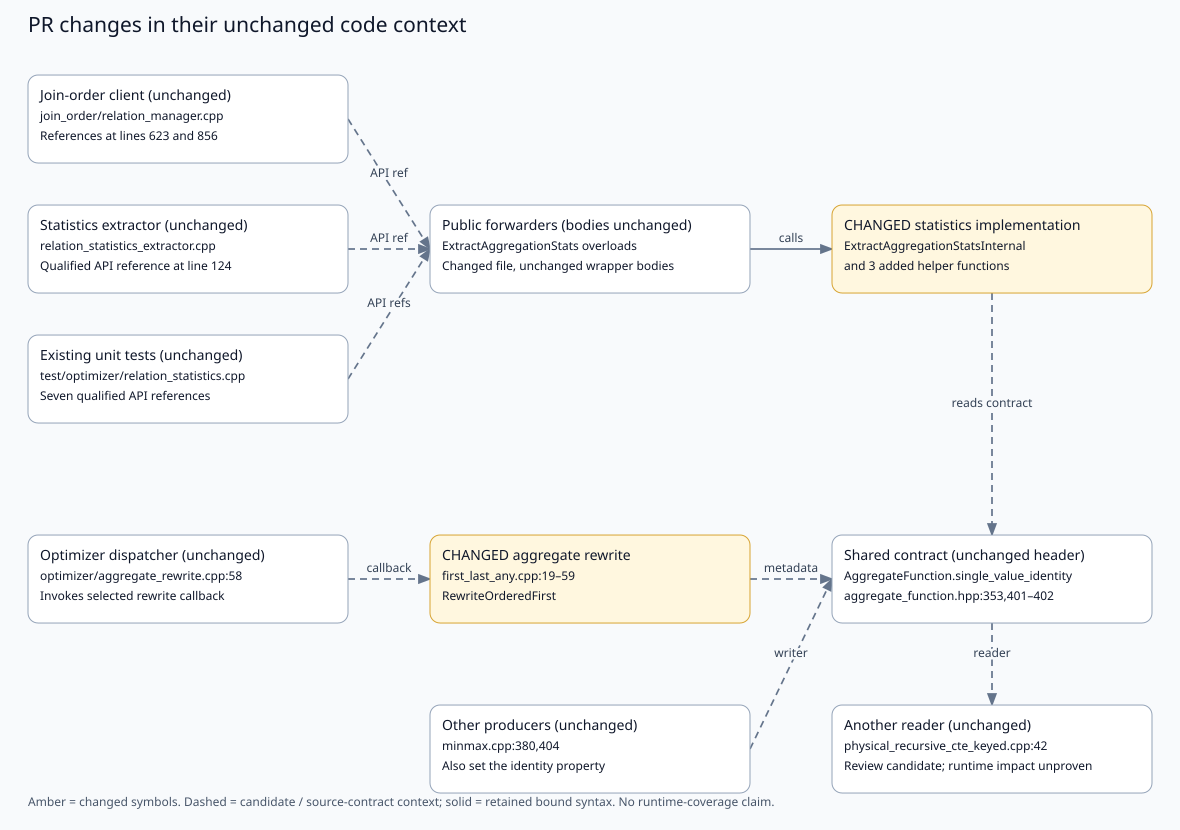

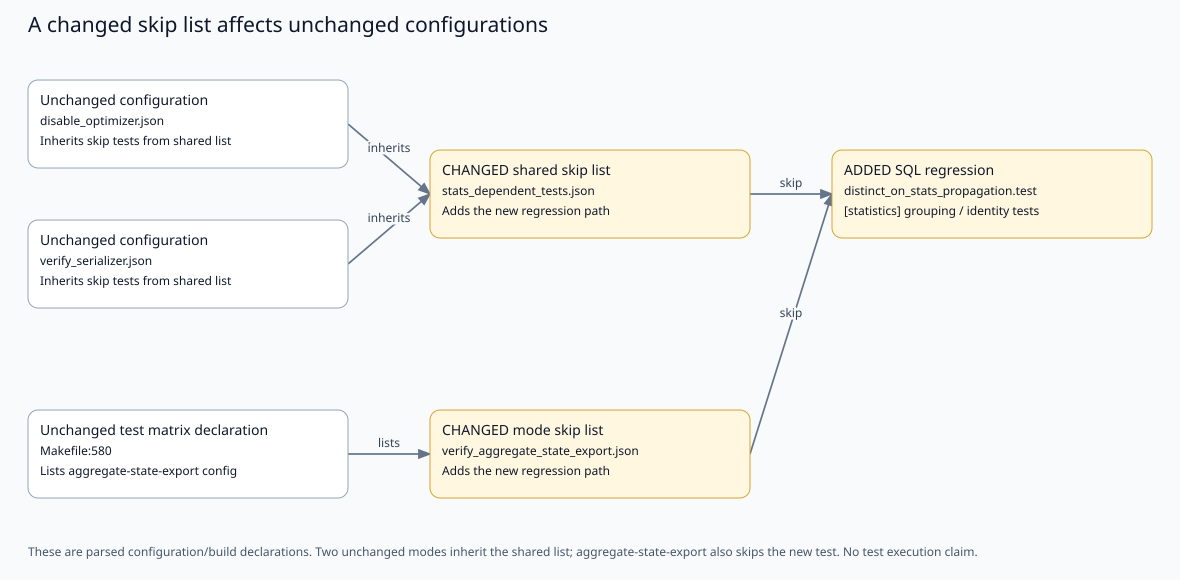

In [24]:
# Diagram edges are backed by the relationship records; dashed edges remain candidates/context.
from IPython.display import SVG
context_render=subprocess.run([sys.executable,str(CONTEXT_ART/'render_context.py')],capture_output=True,text=True)
assert context_render.returncode==0,context_render.stderr
print(context_render.stdout)
display(SVG(filename=str(CONTEXT_ART/'code-context.svg')))
display(SVG(filename=str(CONTEXT_ART/'configuration-context.svg')))

In [22]:
ATTACH IF NOT EXISTS '/Users/kevintruong/project/SpurCode/.spur/artifacts/cpp-gap-repository-index/change-context.duckdb' AS pr_context (READ_ONLY);
-- Change this path to inspect another PR file. The context inventory is all tracked files.
WITH selected AS (
 SELECT 'src/optimizer/relation_statistics/relation_statistics_helper.cpp' AS changed_path
)
SELECT CASE WHEN r.source_path=s.changed_path THEN 'outgoing / membership' ELSE 'incoming / candidate' END AS direction,
       CASE WHEN r.source_path=s.changed_path THEN r.target_path ELSE r.source_path END AS related_path,
       r.relation, r.evidence_class, r.witness_path, r.witness_line
FROM pr_context.relationships r, selected s
WHERE r.source_path=s.changed_path OR r.target_path=s.changed_path
ORDER BY direction,evidence_class,related_path;

direction,related_path,relation,evidence_class,witness_path,witness_line
incoming / candidate,src/optimizer/join_order/relation_manager.cpp,references_aggregate_stats_api,source_reference_candidate,src/optimizer/join_order/relation_manager.cpp,623
incoming / candidate,src/optimizer/join_order/relation_manager.cpp,references_aggregate_stats_api,source_reference_candidate,src/optimizer/join_order/relation_manager.cpp,856
incoming / candidate,src/optimizer/relation_statistics/relation_statistics_extractor.cpp,references_aggregate_stats_api,source_reference_candidate,src/optimizer/relation_statistics/relation_statistics_extractor.cpp,124
incoming / candidate,src/optimizer/relation_statistics/relation_statistics_operator.cpp,unqualified_api_name_candidate,source_reference_candidate,src/optimizer/relation_statistics/relation_statistics_operator.cpp,370
incoming / candidate,test/optimizer/relation_statistics.cpp,references_aggregate_stats_api,source_reference_candidate,test/optimizer/relation_statistics.cpp,1030
incoming / candidate,test/optimizer/relation_statistics.cpp,references_aggregate_stats_api,source_reference_candidate,test/optimizer/relation_statistics.cpp,1034
incoming / candidate,test/optimizer/relation_statistics.cpp,references_aggregate_stats_api,source_reference_candidate,test/optimizer/relation_statistics.cpp,1039
incoming / candidate,test/optimizer/relation_statistics.cpp,references_aggregate_stats_api,source_reference_candidate,test/optimizer/relation_statistics.cpp,1079
incoming / candidate,test/optimizer/relation_statistics.cpp,references_aggregate_stats_api,source_reference_candidate,test/optimizer/relation_statistics.cpp,1402
incoming / candidate,test/optimizer/relation_statistics.cpp,references_aggregate_stats_api,source_reference_candidate,test/optimizer/relation_statistics.cpp,1408


In [23]:
# Check context-map integrity and the concrete review paths, rather than resolution totals.
import gzip, hashlib
tracked_context=json.loads(gzip.decompress((CONTEXT_ART/'tracked-files.json.gz').read_bytes()))
tracked_by_path={r['logical_path']:r for r in tracked_context}
relations=json.loads((CONTEXT_ART/'relationships.json').read_text())
seeds_context=json.loads((CONTEXT_ART/'seed-node-mapping.json').read_text())
effective_context=json.loads((CONTEXT_ART/'effective-test-selection.json').read_text())
assert len(tracked_context)==len(tracked_by_path)==18342
assert len(context_cards)==5 and all(r['unchanged_context_files_within_two_relations'] for r in context_cards)
assert sum(r['changed'] for r in tracked_context)==5
assert all(r['source_path'] in tracked_by_path and r['target_path'] in tracked_by_path and r['witness_path'] in tracked_by_path for r in relations)
assert all(tracked_by_path[r['witness_path']]['blob_oid']==r['witness_blob_oid'] for r in relations)
assert all(r['revision']=='d29b26bb92ac940a0807be0f43cc385b31623839' for r in relations)
assert all(any(p in (r['source_path'],r['target_path']) for r in relations) for p in changed_paths)
assert len(seeds_context)==5 and all(r['captured_nodes'] for r in seeds_context)
identity_context=json.loads((CONTEXT_ART/'identities.json').read_text())
for seed in seeds_context:
    for n in seed['captured_nodes']:
        assert n['graph_identity']==identity_context['retained_native_graph_identity']
        assert n['scoped_node_id']==n['graph_identity']+':'+str(n['node_id'])
        assert n['source_blob_oid']==tracked_by_path[n['path']]['blob_oid']
assert len(forwarders)==2 and all(r['body_unchanged'] for r in forwarders)
assert len(native_context_paths)==15
assert {r['configuration'] for r in effective_context if not r['configuration_changed']}=={'test/configs/disable_optimizer.json','test/configs/verify_serializer.json'}
assert len(effective_context)==4
assert len(json.loads((CONTEXT_ART/'callback-registrations.json').read_text()))==4
assert any(r['source_path']=='src/execution/operator/set/physical_recursive_cte_keyed.cpp' and r['relation']=='reads_shared_identity_contract' and not r['source_changed'] for r in relations)
assert any(r['source_path']=='src/optimizer/join_order/relation_manager.cpp' and r['witness_line']==623 and r['evidence_class']=='source_reference_candidate' for r in relations)
for r in relations:
    for p in [r['source_path'],r['target_path']]:
        if p not in changed_paths: assert tracked_by_path[p]['unchanged_blob_verified'],p
    if r['evidence_class']=='native_bound_syntax':
        witness=Path('/Users/kevintruong/project/SpurCode')/r['evidence_artifact']
        assert witness.read_text().splitlines()[r['evidence_artifact_line']-1]==r['witness_text']
checks={'status':'passed','tracked_file_context':18342,'changed_files_mapped':5,'changed_symbol_seeds_mapped':5,
        'native_two_hop_paths':15,'unchanged_forwarders_verified':2,'effective_skip_configurations':4,
        'unchanged_inheriting_configurations':2,'callback_registrations':4,'relationship_records':len(relations),
        'evidence_types':sorted({r['evidence_class'] for r in relations}),
        'scope':'PR-specific source-backed context mapping. Candidates and shared-contract participation remain distinct from confirmed runtime impact.'}
(CONTEXT_ART/'verification.json').write_text(json.dumps(checks,indent=2))
print(json.dumps(checks,indent=2))

{
  "status": "passed",
  "tracked_file_context": 18342,
  "changed_files_mapped": 5,
  "changed_symbol_seeds_mapped": 5,
  "native_two_hop_paths": 15,
  "unchanged_forwarders_verified": 2,
  "effective_skip_configurations": 4,
  "unchanged_inheriting_configurations": 2,
  "callback_registrations": 4,
  "relationship_records": 332,
  "evidence_types": [
    "build_declaration",
    "callback_dispatch_candidate",
    "config_value",
    "configuration_schema_consumer",
    "native_bound_syntax",
    "shared_contract_reference",
    "source_reference_candidate"
  ],
  "scope": "PR-specific source-backed context mapping. Candidates and shared-contract participation remain distinct from confirmed runtime impact."
}


## What this means for the review app

The changed files/symbols are the selection. The entire tracked repository supplies their context. The map must keep unchanged code and non-code relationships visible:

1. Public clients → unchanged wrapper bodies → changed statistics implementation.
2. Callback registration/dispatch and the shared `single_value_identity` contract → surrounding optimizer and execution code.
3. Changed test skip lists → effective selections in unchanged inheriting configurations.
4. Changed and surrounding files → actual CMake-declared components.

The diagrams and tables retain source witnesses and relationship types. Native bound syntax, reference candidates, possible callback flow, shared-contract participation and parsed configuration effects are different evidence. Their neighborhoods do not automatically become confirmed runtime blast radius.

[Findings, diagrams and app contract](/Users/kevintruong/project/SpurCode/docs/research/2026-11-18-pr28731-change-context.md)

The added context section uses the verified, retained native baseline together with a scan of all tracked text and parsed build/configuration declarations. The earlier baseline remains available below the introduction; no production extractor or extension behavior was changed.